In [44]:
import tomllib
from grokkingexperiments.main import main
from pydantic import BaseModel, PositiveInt, PositiveFloat
from typing import Literal

In [45]:
config = tomllib.load(open("config.toml", "rb"))

In [65]:
class Config(BaseModel):
    model: ModelConfig
    training: TrainingConfig

In [66]:
class ModelConfig(BaseModel):
    actv_func : Literal["relu", "tanh", "sigmoid"]
    embed_dim : PositiveInt
    hidden_dim : PositiveInt


In [67]:
class TrainingConfig(BaseModel):
    n : PositiveInt
    op : Literal["mod_n", "bitwise_and"]
    split : PositiveFloat
    epochs : PositiveInt

In [68]:
config = Config(**config["model"])

ValidationError: 2 validation errors for Config
model
  Field required [type=missing, input_value={'n': 10, 'op': 'mod_n', ...': 256, 'epochs': 10000}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.14/v/missing
training
  Field required [type=missing, input_value={'n': 10, 'op': 'mod_n', ...': 256, 'epochs': 10000}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.14/v/missing

In [42]:
config.op

'mod_n'

Epoch  0      | Loss 2.290  | Test loss 2.427  | Train accuracy 0.150  | Test accuracy 0.017 
Epoch  100    | Loss 0.010  | Test loss 8.252  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  200    | Loss 0.007  | Test loss 8.040  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  300    | Loss 0.006  | Test loss 7.881  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  400    | Loss 0.005  | Test loss 7.757  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  500    | Loss 0.004  | Test loss 7.658  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  600    | Loss 0.004  | Test loss 7.585  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  700    | Loss 0.003  | Test loss 7.539  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  800    | Loss 0.003  | Test loss 7.517  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  900    | Loss 0.003  | Test loss 7.518  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  1000   | Loss 0.002  | Test loss 7.534  | Train accur

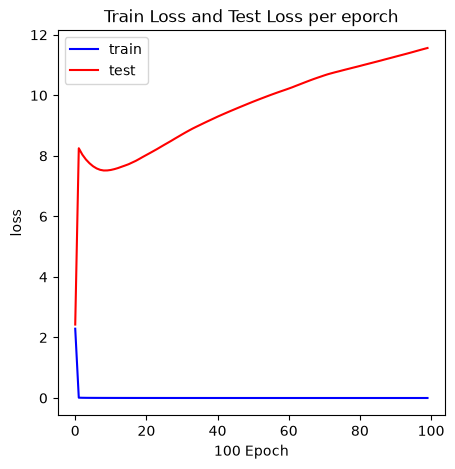

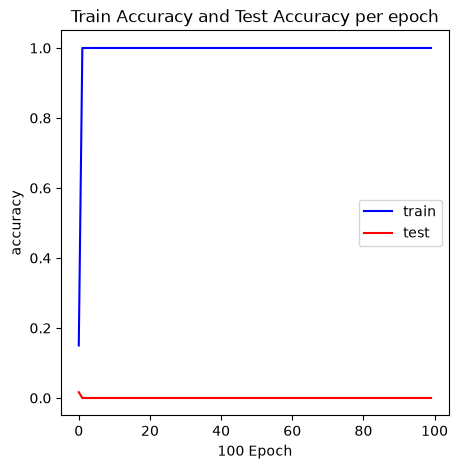

In [43]:
# Operations, splits, seeds, activation functions
main(config.n, config.op, config.split, config.embed_dim, config.hidden_dim, config.epochs)